
# Objetivo
### Mejorar la evaluacion de daños de siniestros de autos, utilizando herramientas de inteligencia artificial como Hugging face, realizo el entrenamiento y la comparación de 3 modelos de visión por computadora: ViT (google/vit-base-patch16-224), ResNet-50 (microsoft/resnet-50) y ConvNeXt (facebook/convnext-tiny-224).
### El dataset que utilizo es de kaggle, Car Damage Detection, obtengo el calculo de metricas (accuracy, precision, recall y F1-score) y comparo la latencia.

# Configuración de GPU

In [1]:
import torch
# Configurar el dispositivo de ejecución
v_device = 0 if torch.cuda.is_available() else -1
print(f"Dispositivo de hardware activo: {'GPU T4' if v_device == 0 else 'CPU'}")

Dispositivo de hardware activo: GPU T4


# Instalacion de dependencias

In [2]:
# 1. Instala las librerías necesarias para Hugging Face, procesamiento de imágenes y scikit-learn.
!pip install -q transformers datasets accelerate scikit-learn pandas pillow torch torchvision
print("Dependencias instaladas correctamente")

Dependencias instaladas correctamente


# Autenticación en Hugging Face Hub

In [4]:
from huggingface_hub import notebook_login
notebook_login()

# Carga de modelos y datasets.

###  Modelos utilizados :
    ViT       : google/vit-base-patch16-224
    ResNet-50 : microsoft/resnet-50
    ConvNeXt  : facebook/convnext-tiny-224

###  Dataset de Kaggle : Car damage detection

In [8]:
import os
import zipfile
import xml.etree.ElementTree as ET
import pandas as pd
import torch
from torch.utils.data import Dataset
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.preprocessing import LabelEncoder
from google.colab import files

# 1. Carga y configuración de los 3 modelos

v_modelos_dict = {
      'ViT': 'google/vit-base-patch16-224',
      'ResNet-50': 'microsoft/resnet-50',
      'ConvNeXt': 'facebook/convnext-tiny-224'
  }

v_processors = {}
v_models = {}

print("Inicia la carga del modelo")
for v_nombre, v_path in v_modelos_dict.items():
    print(f" Cargando {v_nombre} ({v_path})")
    v_processors[v_nombre] = AutoImageProcessor.from_pretrained(v_path)
    v_models[v_nombre] = AutoModelForImageClassification.from_pretrained(
        v_path,
        ignore_mismatched_sizes=True
    )

print("\nFinaliza carga de modelos exitosamente\n")



# 2.Carga de archivo ZIP

print("Por favor, selecciona tu archivo .zip con las imágenes y los XMLs:")

v_uploaded = files.upload()
if v_uploaded:
    v_archivo_zip = list(v_uploaded.keys())[0]
    print(f"\nArchivo seleccionado: {v_archivo_zip}")
else:
    v_archivo_zip = 'dataset_val.zip'

v_ruta_extraccion = './dataset_val'

# Descomprimir el archivo zip
with zipfile.ZipFile(v_archivo_zip, 'r') as zip_ref:
    zip_ref.extractall(v_ruta_extraccion)
print("Archivo ZIP descomprimido exitosamente")

# Recorrer la carpeta buscando archivos XML para extraer nombre de imagen y clase
v_datos = []
for v_raiz, v_dirs, v_archivos in os.walk(v_ruta_extraccion):
    for v_archivo in v_archivos:
        if v_archivo.lower().endswith('.xml'):
            v_xml_path = os.path.join(v_raiz, v_archivo)
            try:
                v_tree = ET.parse(v_xml_path)
                v_root = v_tree.getroot()

                # Extraer nombre del archivo de imagen desde el XML
                v_filename_elem = v_root.find('filename')
                v_filename = v_filename_elem.text if v_filename_elem is not None else v_archivo.replace('.xml', '.jpg')

                # Extraer la clase/etiqueta del objeto anotado
                for v_obj in v_root.findall('object'):
                    v_name_elem = v_obj.find('name')
                    if v_name_elem is not None:
                        v_label = v_name_elem.text
                        v_datos.append({
                            'filename': v_filename,
                            'label_real': v_label
                        })
                        break # Tomamos la primera etiqueta detectada por imagen
            except Exception as e:
                print(f"Error procesando {v_xml_path}: {e}")

v_csv_path = 'dataset_siniestros_procesado.csv'

if len(v_datos) > 0:
    v_df = pd.DataFrame(v_datos)
    v_df.to_csv(v_csv_path, index=False)
    print(f"¡CSV generado con éxito, Total de registros: {len(v_df)}")
else:
    print("No se encontraron archivos XML válidos o etiquetas en la ruta especificada.")

print("\nIniciando carga del dataset")
v_df = pd.read_csv(v_csv_path)

# Codificar etiquetas de texto a índices numéricos
v_label_encoder = LabelEncoder()
v_df['label_idx'] = v_label_encoder.fit_transform(v_df['label_real'])
v_num_clases = len(v_label_encoder.classes_)
print(f"Número de clases detectadas: {v_num_clases}")
print(f"Clases: {v_label_encoder.classes_}")

# Definir clase Dataset personalizada en PyTorch
class DatasetSiniestros(Dataset):
    def __init__(self, df, img_dir, processor):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        nombre_img = row['filename']
        label = row['label_idx']

        img_path = None
        for raiz, dirs, archivos in os.walk(self.img_dir):
            if nombre_img in archivos:
                img_path = os.path.join(raiz, nombre_img)
                break

        if img_path and os.path.exists(img_path):
            imagen = Image.open(img_path).convert('RGB')
        else:
            imagen = Image.new('RGB', (224, 224), color='gray')

        inputs = self.processor(images=imagen, return_tensors="pt")
        item = {k: v.squeeze(0) for k, v in inputs.items()}
        item['labels'] = torch.tensor(label, dtype=torch.long)
        return item

print("\nFinaliza carga del dataset")

Inicia la carga del modelo
 Cargando ViT (google/vit-base-patch16-224)


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

 Cargando ResNet-50 (microsoft/resnet-50)


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

 Cargando ConvNeXt (facebook/convnext-tiny-224)


Loading weights:   0%|          | 0/182 [00:00<?, ?it/s]


Finaliza carga de modelos exitosamente

Por favor, selecciona tu archivo .zip con las imágenes y los XMLs:


Saving valid.zip to valid (1).zip

Archivo seleccionado: valid (1).zip
Archivo ZIP descomprimido exitosamente
¡CSV generado con éxito, Total de registros: 390

Iniciando carga del dataset
Número de clases detectadas: 14
Clases: ['Front-Windscreen-Damage' 'Headlight-Damage' 'Rear-windscreen-Damage'
 'RunningBoard-Dent' 'Sidemirror-Damage' 'Signlight-Damage'
 'Taillight-Damage' 'bonnet-dent' 'doorouter-dent' 'fender-dent'
 'front-bumper-dent' 'quaterpanel-dent' 'rear-bumper-dent' 'roof-dent']

Finaliza carga del dataset


# Pipeline de inferencia

In [9]:
from transformers import Trainer, TrainingArguments, AutoModelForImageClassification

# División Train/Val (80/20) compartida
v_df_train = v_df.sample(frac=0.8, random_state=42)
v_df_val = v_df.drop(v_df_train.index)

# Diccionario con las rutas de los 3 modelos
v_modelos_paths = {
    'ViT': 'google/vit-base-patch16-224',
    'ResNet-50': 'microsoft/resnet-50',
    'ConvNeXt': 'facebook/convnext-tiny-224'
}

v_ruta_imagenes = './dataset_val'

# Diccionario para almacenar los trainers y modelos entrenados de cada arquitectura
v_trainers = {}
v_models_entrenados = {}

print("iniciando entrenamiento de los modelos")

for v_nombre_corto, v_path in v_modelos_paths.items():
    print(f"\nProcesando modelo: {v_nombre_corto}")

    # Cargar el modelo con el número de clases
    v_model = AutoModelForImageClassification.from_pretrained(
        v_path,
        num_labels=v_num_clases,
        ignore_mismatched_sizes=True
    )

    v_processor = v_processors[v_nombre_corto]

    # Crear datasets
    v_train_dataset = DatasetSiniestros(v_df_train, v_ruta_imagenes, v_processor)
    v_val_dataset = DatasetSiniestros(v_df_val, v_ruta_imagenes, v_processor)

    # Argumentos de entrenamiento
    v_training_args = TrainingArguments(
        output_dir=f"./resultados_{v_nombre_corto}",
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=5e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=2,
        weight_decay=0.01,
        load_best_model_at_end=True,
        logging_steps=10,
        fp16=torch.cuda.is_available(),
        report_to="none"
    )

    v_trainer = Trainer(
        model=v_model,
        args=v_training_args,
        train_dataset=v_train_dataset,
        eval_dataset=v_val_dataset,
    )

    print(f"Entrenando {v_nombre_corto}...")
    v_trainer.train()

    # Guardar en los diccionarios para el siguiente paso (métricas y latencia)
    v_trainers[v_nombre_corto] = v_trainer
    v_models_entrenados[v_nombre_corto] = v_model

    print(f"¡{v_nombre_corto} entrenado")

print("Finaliza entrenamiento de los modelos")

[transformers] You passed `num_labels=14` which is incompatible to the `id2label` map of length `1000`.


iniciando entrenamiento de los modelos

Procesando modelo: ViT


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([14, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([14])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Entrenando ViT...


...

Entrenando ConvNeXt...


Epoch,Training Loss,Validation Loss
1,2.544995,2.516076
2,2.366211,2.491361


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

¡ConvNeXt entrenado
Finaliza entrenamiento de los modelos


# Cálculo de métricas (accuracy, precision, recall, F1-score).

In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

print("Inicia calculo de metricas")

v_metricas_resultados = []

for v_nombre_corto, v_trainer in v_trainers.items():
    print(f"\nCalculando métricas para: {v_nombre_corto}...")

    # Evaluar usando el trainer de cada modelo
    v_eval_output = v_trainer.evaluate()

    # Obtener predicciones sobre el conjunto de validación
    v_pred_output = v_trainer.predict(v_val_dataset)
    v_preds = np.argmax(v_pred_output.predictions, axis=1)
    v_labels = v_pred_output.label_ids

    # Calcular métricas explícitas con scikit-learn
    v_acc = accuracy_score(v_labels, v_preds)
    v_precision, v_recall, v_f1, _ = precision_recall_fscore_support(
        v_labels, v_preds, average='weighted', zero_division=0
    )

    v_metricas_resultados.append({
        'Modelo': v_nombre_corto,
        'Accuracy': round(v_acc, 4),
        'Precision': round(v_precision, 4),
        'Recall': round(v_recall, 4),
        'F1-Score': round(v_f1, 4)
    })

# Convertir a DataFrame temporal para visualizar el avance
v_df_metricas = pd.DataFrame(v_metricas_resultados)
print("Finaliza calculo de metricas")
print("\nResultado de las metricas")
display(v_df_metricas)

Inicia calculo de metricas

Calculando métricas para: ViT...


Training Loss,Validation Loss,Epoch
1.254070,2.059120,2



Calculando métricas para: ResNet-50...


Training Loss,Validation Loss,Epoch
2.588489,2.620793,2



Calculando métricas para: ConvNeXt...


Training Loss,Validation Loss,Epoch
2.366211,2.491361,2


Finaliza calculo de metricas

Resultado de las metricas


,Modelo,Accuracy,Precision,Recall,F1-Score
0,ViT,0.2308,0.1853,0.2308,0.1834
1,ResNet-50,0.0897,0.1344,0.0897,0.0666
2,ConvNeXt,0.2308,0.1141,0.2308,0.1445


# Medicion de latencia

In [11]:
import time
import torch
from PIL import Image
import pandas as pd

print("\nInicia medición de latencia\n")

v_device = 'cuda' if torch.cuda.is_available() else 'cpu'
v_latencia_resultados = []

for v_nombre_corto, v_model in v_models_entrenados.items():
    print(f"\nMidiendo latencia para: {v_nombre_corto}...")

    v_processor = v_processors[v_nombre_corto]
    v_model.to(v_device)
    v_model.eval()

    v_latencias = []

    # Realizar múltiples iteraciones de prueba para promediar la latencia
    for _ in range(50):
        v_img_dummy = Image.new('RGB', (224, 224))
        v_inputs = v_processor(images=v_img_dummy, return_tensors="pt").to(v_device)

        v_t_inicio = time.time()
        with torch.no_grad():
            _ = v_model(**v_inputs)
        v_latencia_ms = (time.time() - v_t_inicio) * 1000
        v_latencias.append(v_latencia_ms)

    v_latencia_promedio = sum(v_latencias) / len(v_latencias)

    v_latencia_resultados.append({
        'Modelo': v_nombre_corto,
        'Latencia Prom. (ms)': round(v_latencia_promedio, 2)
    })
print("\nFinaliza medición de latencia")
# Convertir a DataFrame temporal de latencias
v_df_latencias = pd.DataFrame(v_latencia_resultados)
print("\nResultados de la medición de latencia")
display(v_df_latencias)


Inicia medición de latencia


Midiendo latencia para: ViT...

Midiendo latencia para: ResNet-50...

Midiendo latencia para: ConvNeXt...

Finaliza medición de latencia

Resultados de la medición de latencia


,Modelo,Latencia Prom. (ms)
0,ViT,12.04
1,ResNet-50,12.67
2,ConvNeXt,19.78


# Tablas o resumenes


Tabla comparativa de resultado



,Modelo,Accuracy,Precision,Recall,F1-Score,Latencia Prom. (ms)
0,ViT,0.2308,0.1853,0.2308,0.1834,12.04
1,ResNet-50,0.0897,0.1344,0.0897,0.0666,12.67
2,ConvNeXt,0.2308,0.1141,0.2308,0.1445,19.78


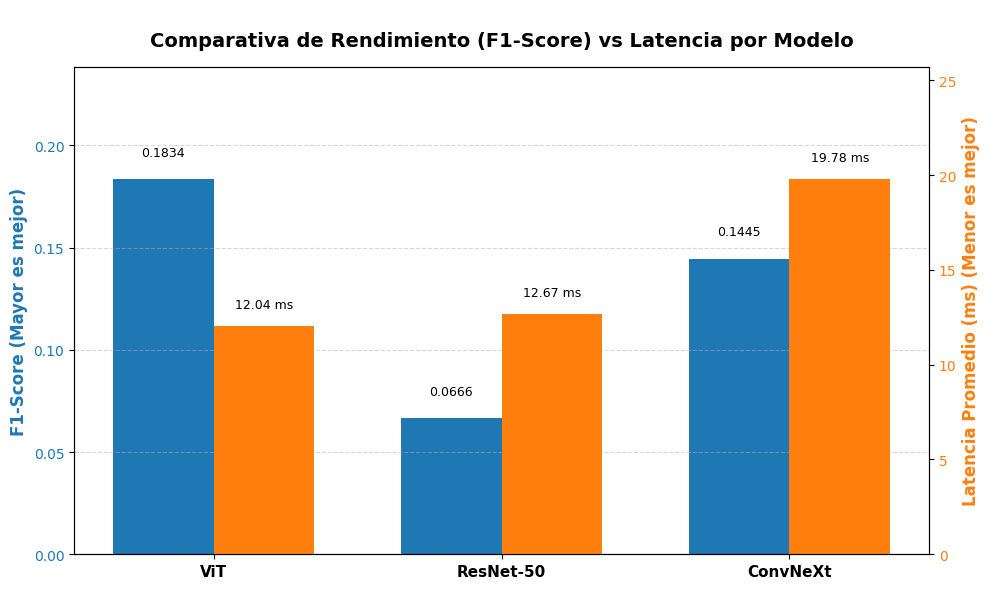

In [12]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("\nTabla comparativa de resultado\n")


# 1. Fusionar resultados de métricas y latencias de forma segura
v_df_metricas_temp = pd.DataFrame(v_metricas_resultados)
v_df_latencias_temp = pd.DataFrame(v_latencia_resultados)
v_df_resumen_final = pd.merge(v_df_metricas_temp, v_df_latencias_temp, on='Modelo')

display(v_df_resumen_final)

# 2. Generar la gráfica extrayendo los datos directamente del DataFrame resultante
v_modelos = v_df_resumen_final['Modelo'].tolist()
v_f1_scores = v_df_resumen_final['F1-Score'].tolist()
v_latencias = v_df_resumen_final['Latencia Prom. (ms)'].tolist()

v_x = np.arange(len(v_modelos))
v_width = 0.35

v_fig, v_ax1 = plt.subplots(figsize=(10, 6))

# Barras de F1-Score (Eje Y izquierdo)
v_bars1 = v_ax1.bar(v_x - v_width/2, v_f1_scores, v_width, label='F1-Score', color='#1f77b4')
v_ax1.set_ylabel('F1-Score (Mayor es mejor)', color='#1f77b4', fontsize=12, fontweight='bold')
v_ax1.tick_params(axis='y', labelcolor='#1f77b4')
v_ax1.set_ylim(0, max(v_f1_scores) * 1.3 if max(v_f1_scores) > 0 else 0.5)

# Segundo eje Y para Latencia (ms)
v_ax2 = v_ax1.twinx()
v_bars2 = v_ax2.bar(v_x + v_width/2, v_latencias, v_width, label='Latencia Prom. (ms)', color='#ff7f0e')
v_ax2.set_ylabel('Latencia Promedio (ms) (Menor es mejor)', color='#ff7f0e', fontsize=12, fontweight='bold')
v_ax2.tick_params(axis='y', labelcolor='#ff7f0e')
v_ax2.set_ylim(0, max(v_latencias) * 1.3 if max(v_latencias) > 0 else 50)

# Configuración de ejes y etiquetas
v_ax1.set_xticks(v_x)
v_ax1.set_xticklabels(v_modelos, fontsize=11, fontweight='bold')
plt.title('\nComparativa de Rendimiento (F1-Score) vs Latencia por Modelo', fontsize=14, fontweight='bold', pad=15)
v_ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Etiquetas numéricas sobre las barras
for bar in v_bars1:
    yval = bar.get_height()
    v_ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f"{yval:.4f}", ha='center', va='bottom', fontsize=9)

for bar in v_bars2:
    yval = bar.get_height()
    v_ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f"{yval:.2f} ms", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


#Conclusiones parciales
Los resultados de las métricas nos indican que ViT es el modelo que obtuvo mejores resultados, registrando un Accuracy y Recall de 0.2308 (23.08%), Precision de 0.1853 (18.53%) y un F1-Score de 0.1834 (18.34%). En segundo lugar está ConvNeXt con un Accuracy y Recall de 0.2308 (23.08%), Precision de 0.1141 (11.41%) y un F1-Score de 0.1445 (14.45%). El tercer lugar es de ResNet-50 con un Accuracy y Recall de 0.0897 (8.97%), Precision de 0.1344 (13.44%) y un F1-Score de 0.0666 (6.66%), presentando el desempeño más bajo de la comparación de los 3 modelos.   En la comparación de latencia, ViT fue el mejor ya que tuvo la menor latencia promedio de 12.04 ms por imagen, por lo que en su procesamiento fue el más rápido utilizando GPU. ResNet-50 fue el segundo lugar con una latencia de 12.67 ms y, por último, ConvNeXt fue el más lento con 19.78 ms.   Como resultado de esta comparación entre métricas y latencia, el modelo más óptimo que se aplica para este caso de uso es **VIT**.


